### Task 5: Run a series of lifetime DEL computations, varying model settings including: 
 - Amount of training data points for the ML models; e.g., 100, 200, 500, 1000, 5000… 
 - Number of points used for integration over the lifetime ($M$ = 103,104,105 …) 
- Multiple realizations with and without considering the effect of the climate uncertainty 
variable $X_W$

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

InputData = pd.read_excel('ML_ExampleDataSet.xlsx','InputVariables')
InputData = InputData.set_index('Sample_No',drop = False) # Make the "Sample_No" column as index of the data

TargetData = pd.read_excel('ML_ExampleDataSet.xlsx','LoadResults')
TargetData.set_index('PointNo', drop = False, inplace = True) # Make the "PointNo" column as index of the data

AllInputData = InputData.where(InputData['Sample_No']==TargetData['PointNo'])
AllTargetData = TargetData.where(TargetData['PointNo']==InputData['Sample_No'])
AllInputData.drop(columns = 'Sample_No', inplace = True)
AllTargetData.drop(columns = 'PointNo', inplace = True)
AllInputData = AllInputData[["U", "SigmaU", "Alpha"]]
nsamples = AllInputData['U'].count() # Find the total number of data points in the data frame
FeatureNames = AllInputData.columns.values
DependentVariableNames = AllTargetData.columns.values

# Load the provided data sets
wind_data = "HovsoreData_Sonic_100m_2004-2013.csv"
del_data = "ML_ExampleDataSet.xlsx"

# Outfput folder location for generated figures
output_figs = "figures/"
os.makedirs(output_figs, exist_ok=True)

# Read the data into pandas DataFrames
df_wind = pd.read_csv(wind_data)
df_del = pd.read_excel(del_data)

# Clean the data
df_wind = df_wind.dropna(subset=["Wsp","TI"])
df_wind = df_wind[(df_wind['Wsp'] > 0) & (df_wind['Wsp'] < 30) & (df_wind['TI'] > 0) & (df_wind['TI'] < 1)]

In [6]:
# -------------------------------------------------------------------
# Task 1: Joint distribution of input variables
# -------------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import scipy.optimize as optimize

# Windspeed (U) and turbulence intensity (TI) data
U = df_wind['Wsp'].values
SigmaU = df_wind['TI'].values * U  # Convert TI to standard deviation of wind speed


# === Fit Weibull to u (MLE - Most Likely Estimate) ===
k, _, A = stats.weibull_min.fit(U, floc=0)                  # WEIBULL Distribution fit (floc=0 -> forces the distribution to start at zero)


# === Bin by u, fit Lognormal to sigma_u per bin, then fit a trend curve ===
bins = np.arange(0, 35, 1.0)
centers, means, stds = [], [], []
# lo(wer) and hi(gher) bounds of each bin -> the sigmaU is fitted to the data in that bin
for lo, hi in zip(bins[:-1], bins[1:]):
    s = SigmaU[(U >= lo) & (U < hi)]
    if len(s) < 30:
        continue
    shape, _, scale = stats.lognorm.fit(s, floc=0)          # LOGNORMAL Distribution fit
    centers.append((lo + hi) / 2)
    means.append(scale * np.exp(0.5 * shape**2))
    stds.append(means[-1] * np.sqrt(np.exp(shape**2) - 1))

# Fit a quadratic curve to the mean -> that is what 2 is indicating 
p_mean = np.polyfit(centers, means, 2)
p_std = np.polyfit(centers, stds, 2)
u_max_fit = max(centers)  # clip point to avoid extrapolation blowing up

In [7]:
# -------------------------------------------------------------------
# Task 2: Uncertainty propagation for lifetime DEL
# -------------------------------------------------------------------
import numpy as np
from scipy import stats

def bootstrap_xw(U, block_days=None, Nbootstrap=5000, measurement_cov=0.01, joint_fit_cov=0.01, seed=1):
    rng = np.random.default_rng(seed)
    baseline_mean_u = np.mean(U)
    N = len(U)
    BootstrapMeans = np.empty(Nbootstrap)

    # IID bootstrap (no block structure)
    if block_days is None:
        for i in range(Nbootstrap):
            bootstrap_sample = rng.choice(U, size=N, replace=True)
            measurement_factor = (1.0 + rng.normal(0, measurement_cov))
            BootstrapMeans[i] = (np.mean(bootstrap_sample) * measurement_factor)

    # Block bootstrap
    else:
        block_size = int(block_days * 144) # 144 records/day
        for i in range(Nbootstrap):
            bootstrap_series = []
            while len(bootstrap_series) < N:
                start = rng.integers(0, N)
                idx = (np.arange(start, start + block_size) % N)
                bootstrap_series.extend(U[idx])
            bootstrap_series = np.asarray(bootstrap_series[:N])
            measurement_factor = (1.0 + rng.normal(0, measurement_cov))
            BootstrapMeans[i] = (np.mean(bootstrap_series)* measurement_factor)
    Xw_bootstrap = BootstrapMeans / baseline_mean_u
    joint_fit_factor = (1.0 + rng.normal(0, joint_fit_cov, Nbootstrap))
    Xw = Xw_bootstrap * joint_fit_factor

    return Xw[Xw > 0]

Xw_365d = bootstrap_xw(U, block_days=365)

In [8]:
# -------------------------------------------------------------------
# Task 3: ML Model for short-term load prediction
# -------------------------------------------------------------------
import sklearn
import sklearn.neural_network

Xscaler = sklearn.preprocessing.StandardScaler().fit(AllInputData.values)
Yscaler = sklearn.preprocessing.StandardScaler().fit(AllTargetData['Blade_root_flapwise_M_x'].values.reshape(-1, 1))

Xtrain = Xscaler.transform(AllInputData.values)
Ytrain = Yscaler.transform(AllTargetData['Blade_root_flapwise_M_x'].values.reshape(-1, 1))

ANNmodel = sklearn.neural_network.MLPRegressor()
ANNmodel.set_params(activation='tanh', hidden_layer_sizes=(8, 8), max_iter=5000, random_state=0)
ANNmodel.fit(Xtrain, Ytrain)


c:\PythonVattenfall\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(8, ...)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'tanh'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",5000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.

In [9]:
# -------------------------------------------------------------------
# Task 5: Lifetime DEL calculation
# -------------------------------------------------------------------
def run_lifetime_DEL(ANNmodel, Xscaler, Yscaler, N_outer=500, N_inner=10000, use_Xw=True):

    m = 10
    n_ref = 600
    N_life = 20 * 365 * 24 * 6
    LifetimeDELs = []

    for i in range(N_outer):

        # Climate uncertainty
        if use_Xw:
            Xw = np.random.choice(Xw_365d)
        else:
            Xw = 1.0

        # U
        U_MC = Xw * stats.weibull_min.rvs(c=k, scale=A, size=N_inner)
        U_clip = np.minimum(U_MC, u_max_fit)

        # SigmaU|U
        sigma_mean = np.polyval(p_mean, U_clip)
        sigma_std = np.polyval(p_std, U_clip)
        SigmaU_MC = np.random.normal(sigma_mean, sigma_std)
        SigmaU_MC = np.maximum(SigmaU_MC, 0.01)

        # Alpha|U
        Alpha_MC = np.random.normal(loc=0.1, scale=np.minimum(1.0,1.0/U_MC))

        # Get the Xmc
        X_MC = np.column_stack([U_MC, SigmaU_MC, Alpha_MC])

        # ANN
        X_MC_scaled = Xscaler.transform(X_MC)

        Loads = Yscaler.inverse_transform(ANNmodel.predict(X_MC_scaled).reshape(-1,1)).flatten()
        Loads = np.maximum(Loads,0)
        MeanDamage = np.mean(Loads**m)
        DEL_LT = ((N_life/n_ref) * MeanDamage)**(1/m)
        LifetimeDELs.append(DEL_LT)

    return np.array(LifetimeDELs)

### A. Vary Training Set Size

In [49]:
all_data = AllInputData.size
training_sizes = [100, 200, 500, 1000, 5000, 10000, 20000, 25000]

for set in training_sizes:
    ratio = set / all_data
    print(f"Training size {set} -> {ratio * 100:.2f}%")

Training size 100 -> 0.33%
Training size 200 -> 0.67%
Training size 500 -> 1.67%
Training size 1000 -> 3.34%
Training size 5000 -> 16.70%
Training size 10000 -> 33.40%
Training size 20000 -> 66.80%
Training size 25000 -> 83.50%


In [50]:
MeanDEL = []
StdDEL = []

for Ntrain in training_sizes:

    X_subset = AllInputData.iloc[:Ntrain]
    Y_subset = AllTargetData.iloc[:Ntrain]

    Xscaler = sklearn.preprocessing.StandardScaler().fit(X_subset.values)
    Yscaler = sklearn.preprocessing.StandardScaler().fit(Y_subset['Blade_root_flapwise_M_x'].values.reshape(-1,1))

    Xtrain = Xscaler.transform(X_subset.values)
    Ytrain = Yscaler.transform(Y_subset['Blade_root_flapwise_M_x'].values.reshape(-1,1))

    ANNmodel = sklearn.neural_network.MLPRegressor(activation='tanh', hidden_layer_sizes=(8,8), max_iter=5000 ,random_state=1)
    ANNmodel.fit(Xtrain,Ytrain)

    DELs = run_lifetime_DEL(ANNmodel, Xscaler, Yscaler)
    MeanDEL.append(np.mean(DELs))
    StdDEL.append(np.std(DELs))

c:\PythonVattenfall\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\PythonVattenfall\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\PythonVattenfall\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\PythonVattenfall\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vecto

Text(0, 0.5, 'Mean Lifetime DEL')

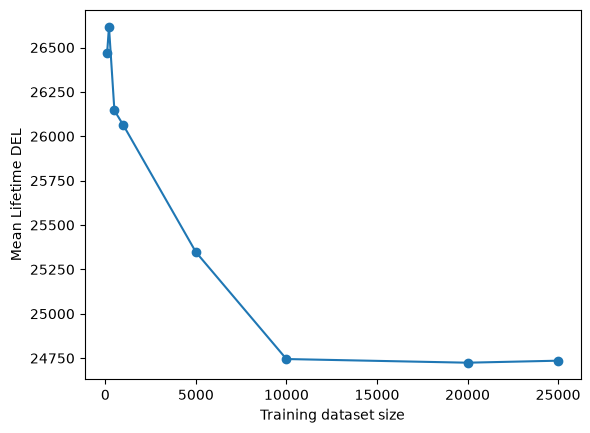

In [51]:
plt.plot(training_sizes, MeanDEL, 'o-')
plt.xlabel("Training dataset size")
plt.ylabel("Mean Lifetime DEL")

Text(0, 0.5, 'Standard Deviation Lifetime DEL')

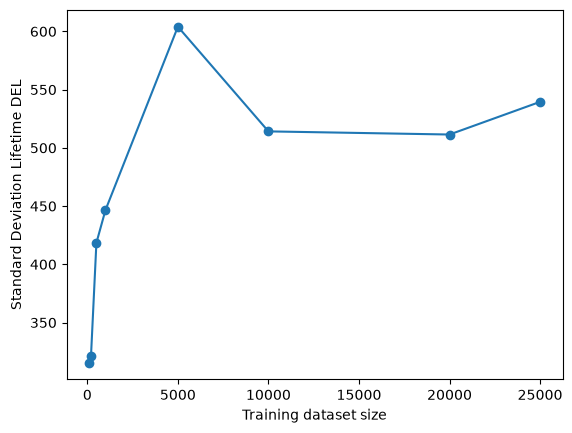

In [52]:
plt.plot(training_sizes, StdDEL, 'o-')
plt.xlabel("Training dataset size")
plt.ylabel("Standard Deviation Lifetime DEL")

### B. Vary Integration Points

In [12]:
integration_sizes = [100, 1000, 10000, 100000]

DEL_mean = []

for M in integration_sizes:
    DELs = run_lifetime_DEL(ANNmodel, Xscaler, Yscaler, N_inner=M)
    DEL_mean.append(np.mean(DELs))

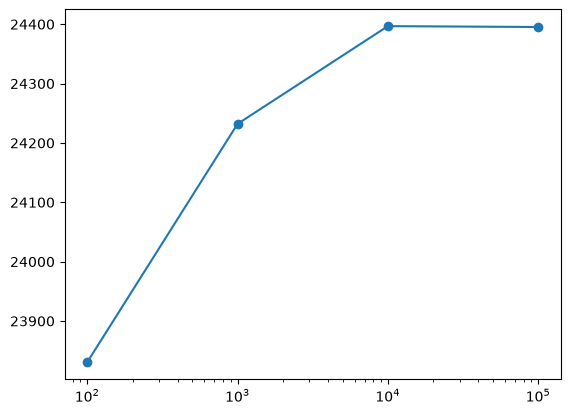

In [13]:
plt.semilogx(integration_sizes, DEL_mean, 'o-')

### C. With and without Climate Uncertainty

In [14]:
DEL_with = run_lifetime_DEL(ANNmodel, Xscaler, Yscaler, use_Xw=True)
DEL_without = run_lifetime_DEL(ANNmodel, Xscaler, Yscaler, use_Xw=False)

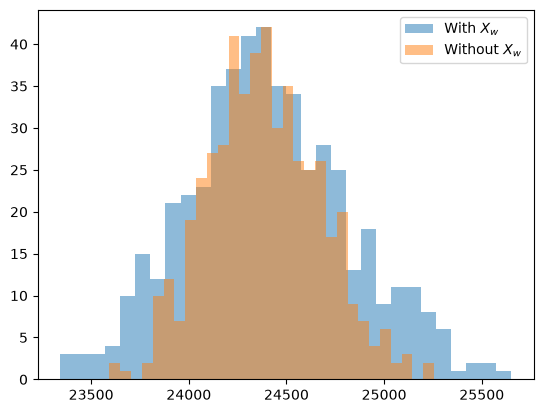

In [48]:
plt.hist(DEL_with, alpha=0.5, bins=30, label=r'With $X_w$')
plt.hist(DEL_without, alpha=0.5, bins=30, label=r'Without $X_w$')
plt.legend()